# 01 · Routing, duration & continuity, currency conversions
Feature groups: **Payment Routing**, **Duration & Continuity**, **Currency Conversions**.

Each section follows the same loop: **hypothesis → test on all 10M rows → confounder check → rule with size and scope → status.**

In [24]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## A. Payment routing
### H-A1  `PARTICIPANT_COUNT` is the number of banks in `BIC8_PATH`; `Direct` means exactly 2 banks

In [25]:
pd.concat([
    rule_check('PARTICIPANT_COUNT = BICs in path', 'PARTICIPANT_COUNT = N_PATH_BICS'),
    rule_check('Direct  <=>  2 participants', "(TRANSACTION_TYPE_CODE='Direct') = (PARTICIPANT_COUNT=2)"),
])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,PARTICIPANT_COUNT = BICs in path,10000000,10000000.0,100.0,0.0
0,Direct <=> 2 participants,10000000,10000000.0,100.0,0.0


### H-A2  The number of intermediaries follows a geometric law (each extra bank is added with a constant probability)

In [26]:
k = q('SELECT PARTICIPANT_COUNT k, count(*) n FROM f GROUP BY 1 ORDER BY 1')
k['share'] = k.n / k.n.sum()
k['ratio_to_previous'] = k.n / k.n.shift(1)
export(k, 'routing_participant_count'); k.head(12)

,k,n,share,ratio_to_previous
0,2,6323280,0.632328,NaN
1,3,2324319,0.232432,0.367581
2,4,855386,0.085539,0.368016
3,5,314014,0.031401,0.367102
4,6,115701,0.011570,0.368458
5,7,42622,0.004262,0.368381
6,8,15481,0.001548,0.363216
7,9,5758,0.000576,0.371940
8,10,2205,0.000220,0.382945
9,11,769,0.000077,0.348753


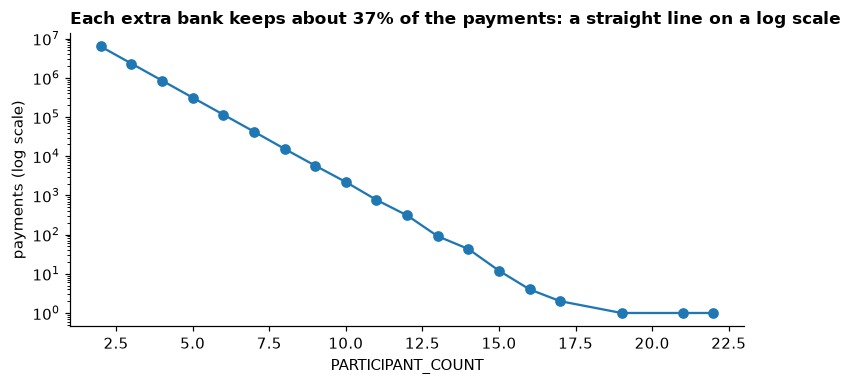

In [27]:
fig, ax = plt.subplots(figsize=(7,3.6))
ax.semilogy(k.k, k.n, 'o-'); ax.set_xlabel('PARTICIPANT_COUNT'); ax.set_ylabel('payments (log scale)')
r = k.ratio_to_previous[1:7].mean()
ax.set_title(f'Each extra bank keeps about {r:.0%} of the payments: a straight line on a log scale')
savefig('A2_participant_count_geometric')

A straight line on a log axis = constant ratio = geometric distribution. Confounder check: is the ratio the same for every customer flow and for domestic vs cross-border?

In [28]:
q('''SELECT FLOW, IS_DOMESTIC, count(*) n,
            avg((PARTICIPANT_COUNT>=3)::int) AS p_ge3,
            sum((PARTICIPANT_COUNT>=4)::int)/sum((PARTICIPANT_COUNT>=3)::int) AS p_ge4_given_ge3,
            sum((PARTICIPANT_COUNT>=5)::int)/sum((PARTICIPANT_COUNT>=4)::int) AS p_ge5_given_ge4
     FROM f GROUP BY ALL ORDER BY 2,1''')

,FLOW,IS_DOMESTIC,n,p_ge3,p_ge4_given_ge3,p_ge5_given_ge4
0,B2B,False,2110359,0.367952,0.368398,0.365990
1,B2C,False,5205675,0.367664,0.367724,0.367047
2,C2B,False,568341,0.368217,0.368404,0.367161
3,C2C,False,1404509,0.367148,0.367075,0.370200
4,B2B,True,160586,0.366178,0.369981,0.372449
5,B2C,True,398017,0.367866,0.367423,0.369463
6,C2B,True,42264,0.366529,0.364470,0.371945
7,C2C,True,110249,0.368466,0.368067,0.369850


### H-A3  Among routed payments (3+ banks) a fixed share is `Covered`, independent of path length

In [29]:
cov = q('''SELECT PARTICIPANT_COUNT k, count(*) n, avg((TRANSACTION_TYPE_CODE='Covered')::int) AS share_covered
             FROM f WHERE PARTICIPANT_COUNT BETWEEN 3 AND 9 GROUP BY 1 ORDER BY 1'''); export(cov,'routing_covered_share'); cov

,k,n,share_covered
0,3,2324319,0.113179
1,4,855386,0.112896
2,5,314014,0.113339
3,6,115701,0.113050
4,7,42622,0.113204
5,8,15481,0.114334
6,9,5758,0.118965


In [30]:
q('''SELECT FLOW, IS_DOMESTIC, count(*) n, avg((TRANSACTION_TYPE_CODE='Covered')::int) AS share_covered,
            avg(LOG10_USD) FILTER (TRANSACTION_TYPE_CODE='Covered') AS mean_log_amt_covered,
            avg(LOG10_USD) FILTER (TRANSACTION_TYPE_CODE='Indirect') AS mean_log_amt_indirect
     FROM f WHERE PARTICIPANT_COUNT>=3 GROUP BY ALL ORDER BY 2,1''')

,FLOW,IS_DOMESTIC,n,share_covered,mean_log_amt_covered,mean_log_amt_indirect
0,B2B,False,776511,0.104819,4.391714,4.318877
1,B2C,False,1913939,0.107734,3.516584,3.449540
2,C2B,False,209273,0.105427,3.517627,3.465806
3,C2C,False,515663,0.104882,2.671055,2.609899
4,B2B,True,58803,0.196248,4.524916,4.557375
5,B2C,True,146417,0.205693,3.658580,3.681585
6,C2B,True,15491,0.183009,3.668211,3.655989
7,C2C,True,40623,0.190360,2.776948,2.824953


### H-A4  Endpoint mismatch: when the path does not start at `ORDERING_BIC8`, is it another bank of the same country?

In [31]:
q('''SELECT PATH_FIRST_IS_ORD, PATH_LAST_IS_BEN, count(*) n,
            avg((substr(string_split(BIC8_PATH,';')[1],5,2)=ORD_COUNTRY)::int)  AS first_same_country_as_ord,
            avg((substr(string_split(BIC8_PATH,';')[-1],5,2)=BEN_COUNTRY)::int) AS last_same_country_as_ben,
            avg((substr(string_split(BIC8_PATH,';')[1],1,4)=substr(ORDERING_BIC8,1,4))::int) AS first_same_4digit_prefix
     FROM f GROUP BY ALL ORDER BY n DESC''')

,PATH_FIRST_IS_ORD,PATH_LAST_IS_BEN,n,first_same_country_as_ord,last_same_country_as_ben,first_same_4digit_prefix
0,True,True,9027029,1.000000,1.000000,1.000000
1,True,False,474572,1.000000,0.058779,1.000000
2,False,True,473706,0.048249,1.000000,0.004406
3,False,False,24693,0.049366,0.057992,0.004900


## B. Duration & continuity
### H-B1  `CONTINUITY_QFLAG='N'` is exactly "path contains `...`", and each link is hidden independently with probability 5%
If every one of the k−1 links is hidden independently with probability p, then P(gap) = 1 − (1−p)^(k−1).

In [32]:
gap = q('''SELECT PARTICIPANT_COUNT k, count(*) n, avg(HAS_GAP::int) AS observed_p_gap
             FROM f GROUP BY 1 HAVING count(*) >= 300 ORDER BY 1''')
gap['model_p_5pct_per_link'] = 1 - 0.95 ** (gap.k - 1)
gap['implied_p_per_link'] = 1 - (1 - gap.observed_p_gap) ** (1 / (gap.k - 1))
export(gap, 'continuity_gap_model'); gap

,k,n,observed_p_gap,model_p_5pct_per_link,implied_p_per_link
0,2,6323280,0.049858,0.050000,0.049858
1,3,2324319,0.097410,0.097500,0.049953
2,4,855386,0.142464,0.142625,0.049941
3,5,314014,0.184957,0.185494,0.049843
4,6,115701,0.225270,0.226219,0.049767
5,7,42622,0.269274,0.264908,0.050943
6,8,15481,0.308378,0.301663,0.051310
7,9,5758,0.330497,0.336580,0.048916
8,10,2205,0.382766,0.369751,0.052200
9,11,769,0.420026,0.401263,0.053020


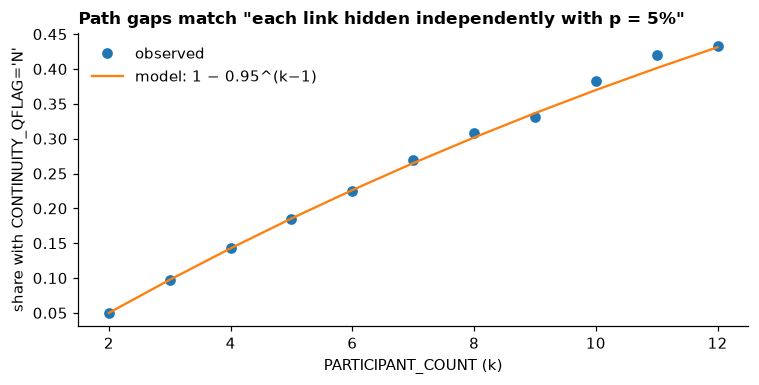

In [33]:
fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(gap.k, gap.observed_p_gap, 'o', label='observed'); ax.plot(gap.k, gap.model_p_5pct_per_link, '-', label='model: 1 − 0.95^(k−1)')
ax.set_xlabel('PARTICIPANT_COUNT (k)'); ax.set_ylabel("share with CONTINUITY_QFLAG='N'"); ax.legend(frameon=False)
ax.set_title('Path gaps match "each link hidden independently with p = 5%"'); savefig('B1_gap_model')

In [34]:
# where does the '...' sit, and how many gaps per path?
q('''SELECT PARTICIPANT_COUNT k, len(string_split(BIC8_PATH,';')) - N_PATH_BICS AS n_gaps, count(*) n
     FROM f WHERE PARTICIPANT_COUNT<=4 GROUP BY ALL ORDER BY 1,2''')

,k,n_gaps,n
0,2,0,6008014
1,2,1,299417
2,2,2,15076
3,2,3,739
4,2,4,30
5,2,5,4
6,3,0,2097906
7,3,1,209705
8,3,2,15638
9,3,3,998


### H-B2  `TOTAL_DURATION` is a sum of per-hop delays: it grows with the number of banks, not with amount or flow

In [35]:
dur = q('''SELECT PARTICIPANT_COUNT k, count(*) n, min(TOTAL_DURATION) mn,
                  quantile_cont(TOTAL_DURATION,0.25) q25, median(TOTAL_DURATION) med,
                  quantile_cont(TOTAL_DURATION,0.75) q75, avg(TOTAL_DURATION) mean, stddev(TOTAL_DURATION) sd
           FROM f WHERE PARTICIPANT_COUNT<=9 GROUP BY 1 ORDER BY 1'''); export(dur,'duration_by_participants'); dur

,k,n,mn,q25,med,q75,mean,sd
0,2,6323280,2,21.00,39.0,877.0,663.308874,1133.421110
1,3,2324319,3,32.00,126.0,1294.0,840.982243,1266.715596
2,4,855386,4,47.00,418.0,1641.0,1042.037762,1394.128857
3,5,314014,6,67.00,590.0,1953.0,1242.206752,1510.434286
4,6,115701,7,133.00,796.0,2250.0,1436.911885,1613.505784
5,7,42622,11,292.00,1033.0,2551.0,1648.966613,1730.646093
6,8,15481,15,409.00,1236.0,2807.0,1834.227505,1830.425302
7,9,5758,25,517.25,1480.0,3078.5,2023.557485,1917.703939


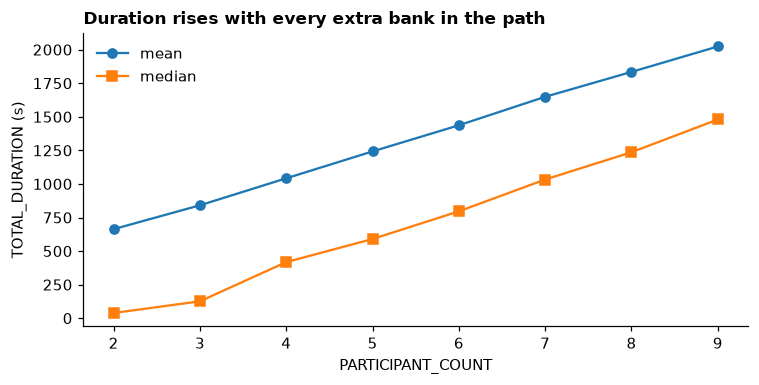

In [36]:
fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(dur.k, dur['mean'], 'o-', label='mean'); ax.plot(dur.k, dur.med, 's-', label='median')
ax.set_xlabel('PARTICIPANT_COUNT'); ax.set_ylabel('TOTAL_DURATION (s)'); ax.legend(frameon=False)
ax.set_title('Duration rises with every extra bank in the path'); savefig('B2_duration_by_participants')

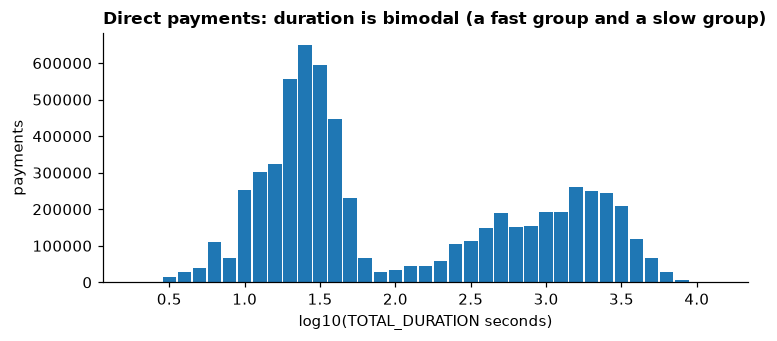

In [37]:
# shape of the duration distribution for the simplest case (Direct): is it a mixture?
h = q('''SELECT round(log10(TOTAL_DURATION),1) lg, count(*) n FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(7,3.2)); ax.bar(h.lg, h.n, width=0.09)
ax.set_xlabel('log10(TOTAL_DURATION seconds)'); ax.set_ylabel('payments')
ax.set_title('Direct payments: duration is bimodal (a fast group and a slow group)'); savefig('B2_duration_direct_bimodal')

In [38]:
# what separates the fast and the slow group? candidate drivers one at a time
for col in ['CURRENCY_CONVERSION_COUNT','IS_DOMESTIC','FLOW','IS_WEEKEND','HAS_GAP','PATH_FIRST_IS_ORD']:
    display(q(f'''SELECT {col}, count(*) n, avg((TOTAL_DURATION>300)::int) AS share_slow, median(TOTAL_DURATION) med
                  FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1'''))

,CURRENCY_CONVERSION_COUNT,n,share_slow,med
0,0,991870,0.394148,45.0
1,1,5331410,0.357102,38.0


,IS_DOMESTIC,n,share_slow,med
0,False,5873498,0.358131,39.0
1,True,449782,0.425359,56.0


,FLOW,n,share_slow,med
0,B2B,1435631,0.360305,39.0
1,B2C,3543336,0.360778,39.0
2,C2B,385841,0.372101,40.0
3,C2C,958472,0.371012,39.0


,IS_WEEKEND,n,share_slow,med
0,False,5616017,0.363067,39.0
1,True,707263,0.361691,39.0


,HAS_GAP,n,share_slow,med
0,False,6008014,0.362864,39.0
1,True,315266,0.363842,39.0


,PATH_FIRST_IS_ORD,n,share_slow,med
0,False,315047,0.363327,39.0
1,True,6008233,0.362891,39.0


In [39]:
q('''SELECT HOUR_UTC, count(*) n, avg((TOTAL_DURATION>300)::int) AS share_slow FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1''').T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
HOUR_UTC,0.000000,1.000000,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,8.000000,9.000000,10.000000,11.000000,12.00000,13.000000,14.000000,15.000000,16.000000,17.000000,18.000000,19.000000,20.000000,21.000000,22.000000,23.000000
n,195148.000000,163431.000000,147411.000000,137800.000000,142586.000000,195159.000000,308739.000000,317737.000000,295277.000000,295444.000000,279697.000000,273284.000000,351091.00000,319654.000000,317026.000000,370438.000000,361375.000000,347172.000000,323275.000000,266535.000000,232413.000000,229847.000000,211352.000000,241389.000000
share_slow,0.356048,0.359809,0.364966,0.367939,0.371151,0.363903,0.362815,0.366375,0.364824,0.366117,0.368985,0.370281,0.36151,0.363527,0.362415,0.358621,0.360894,0.363344,0.362824,0.364526,0.362037,0.358573,0.357475,0.353645


In [40]:
q('''SELECT round(LOG10_USD) AS log10_amount, count(*) n, avg((TOTAL_DURATION>300)::int) AS share_slow, median(TOTAL_DURATION) med
     FROM f WHERE PARTICIPANT_COUNT=2 GROUP BY 1 ORDER BY 1''')

,log10_amount,n,share_slow,med
0,-2.0,345,0.434783,45.0
1,-1.0,1735,0.470317,126.0
2,-0.0,25557,0.422663,45.0
3,1.0,202816,0.404534,43.0
4,2.0,870128,0.382491,41.0
5,3.0,1925184,0.366551,39.0
6,4.0,2047168,0.354586,39.0
7,5.0,1006961,0.349973,38.0
8,6.0,222015,0.346292,38.0
9,7.0,20511,0.342158,38.0


## C. Currency conversions
### H-C1  A conversion can happen on each link; `CURRENCY_CONVERSION_COUNT` ≤ k−1

In [41]:
rule_check('FX count <= PARTICIPANT_COUNT - 1', 'CURRENCY_CONVERSION_COUNT <= PARTICIPANT_COUNT - 1')

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,FX count <= PARTICIPANT_COUNT - 1,10000000,10000000.0,100.0,0.0


### H-C2  A link converts when it crosses a country border (domestic links do not convert)
Simplest clean test: Direct payments with a fully visible path (one link only).

In [42]:
fx1 = q('''SELECT N_PATH_COUNTRIES = 1 AS link_within_one_country, CURRENCY_CONVERSION_COUNT fx, count(*) n
             FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP GROUP BY ALL ORDER BY 1,2''')
fx1['share_within_group'] = fx1.n / fx1.groupby('link_within_one_country').n.transform('sum'); export(fx1,'fx_direct_border'); fx1

,link_within_one_country,fx,n,share_within_group
0,False,0,504779,0.090615
1,False,1,5065788,0.909385
2,True,0,437447,1.000000


Same-country links never convert (0 exceptions). Cross-border links convert about 91% of the time. **What explains the 9% that do not?** Candidate: the two countries share a currency, or the payment currency is the home currency on both sides.

In [43]:
# country pairs that (almost) never convert although they cross a border
pairs = q('''SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2,
                    count(*) n, avg(CURRENCY_CONVERSION_COUNT) p_convert
             FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP AND N_PATH_COUNTRIES=2 GROUP BY ALL HAVING count(*)>=500''')
print('pairs:', len(pairs)); print(pairs.p_convert.round(1).value_counts().sort_index())
pairs.sort_values('p_convert').head(25)

pairs: 1608
p_convert
0.0     150
1.0    1458
Name: count, dtype: int64


,c1,c2,n,p_convert
1552,SI,DE,663,0.0
1564,MC,FI,692,0.0
1520,LU,MC,943,0.0
1463,US,BQ,1075,0.0
1450,MC,NL,899,0.0
1451,IT,MC,1131,0.0
1438,IE,IT,825,0.0
1406,LU,AT,1128,0.0
1385,FI,ES,1331,0.0
1368,US,VG,1360,0.0


In [44]:
# data-driven currency zones: countries linked by never-converting pairs
import networkx as nx
G = nx.Graph(); G.add_edges_from(pairs[pairs.p_convert < 0.02][['c1','c2']].itertuples(index=False))
zones = sorted([sorted(c) for c in nx.connected_components(G)], key=len, reverse=True)
for z in zones: print(len(z), z)

19 ['AD', 'AT', 'BE', 'CY', 'DE', 'ES', 'FI', 'FR', 'IE', 'IT', 'LT', 'LU', 'LV', 'MC', 'MQ', 'MT', 'NL', 'PT', 'SI']
5 ['BQ', 'EC', 'PR', 'US', 'VG']
3 ['GB', 'IM', 'JE']
2 ['CH', 'LI']


In [45]:
# test the zone rule on ALL direct visible payments
zone_of = {c: i for i, z in enumerate(zones) for c in z}
zdf = pd.DataFrame({'country': list(zone_of), 'zone': list(zone_of.values())})
from utils import con; con.register('zdf', zdf)
q('''WITH d AS (SELECT substr(string_split(BIC8_PATH,';')[1],5,2) c1, substr(string_split(BIC8_PATH,';')[2],5,2) c2, CURRENCY_CONVERSION_COUNT fx
               FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP)
     SELECT coalesce('Z'||z1.zone::varchar, c1) = coalesce('Z'||z2.zone::varchar, c2) AS same_currency_area, fx, count(*) n
     FROM d LEFT JOIN zdf z1 ON z1.country=c1 LEFT JOIN zdf z2 ON z2.country=c2 GROUP BY ALL ORDER BY 1,2''')

,same_currency_area,fx,n
0,False,0,14965
1,False,1,5065788
2,True,0,927261


### H-C3  For longer paths the FX count is the number of links that cross a currency border

In [46]:
q('''WITH t AS (SELECT ROW_ID, CURRENCY_CONVERSION_COUNT fx, list_transform(string_split(BIC8_PATH,';'), lambda x: substr(x,5,2)) cs
               FROM f WHERE NOT HAS_GAP AND PARTICIPANT_COUNT BETWEEN 3 AND 6),
          u AS (SELECT ROW_ID, fx, unnest(cs) c, generate_subscripts(cs,1) i FROM t),
          z AS (SELECT u.*, coalesce('Z'||zdf.zone::varchar, c) area FROM u LEFT JOIN zdf ON zdf.country=u.c),
          w AS (SELECT ROW_ID, fx, area, lag(area) OVER (PARTITION BY ROW_ID ORDER BY i) prev FROM z)
     SELECT count(*) AS n_paths, avg((fx = crossings)::int) AS share_fx_equals_area_crossings
     FROM (SELECT ROW_ID, any_value(fx) fx, sum((prev IS NOT NULL AND prev<>area)::int) crossings FROM w GROUP BY 1)''')

,n_paths,share_fx_equals_area_crossings
0,3177002,0.995021
